> # HW 8 - Charlie Caravati


In [32]:
import matplotlib.pyplot as plt
import numpy as np
import numpy.linalg as la
import math
from math import factorial
from numpy.linalg import inv 
from numpy.linalg import norm

> ## 1. 

The hermite polynomial that interpolates the data $\{(x_j, f(x_j)), (x_j, f'(x_j))\}_{j=0}^n$ can be expressed as 

$p_{2n+1}(x) = \sum_{j=0}^n f(x_j)Q_j(x) + \sum_{j=0}^n f'(x_j)R_j(x)$

where $Q_j(x) = [1-2(x-x_j)l'(x_j)]l_j^2(x), R_j(x) = (x-x_j)l_j^2(x)$ and $l_j(x)$ is the $j^{th}$ Lagrange polynomial $l_j(x_i) = 1$ for $x_j$ but 0 for all other $x_i$.

> ### (a)

When evaluated at the interpolation nodes, $Q_j(x)$ must be equal to 1 for $x_j$ and 0 for all other $x_i$. The derivative, $Q'_j(x)$ must be 0 for all $x_i$, including $x_j$. $R_j(x)$ must be 0 for all $x_i$ including $x_j$, but the derivative $R'_j(x)$ must be equal to 1 for $x_j$ but 0 for all other $x_i$.

> ### (b)

To verify $Q_j(x)$ and  $R_j(x)$ are valid basis functions we test the conditions above.

At $x_j$, $Q_j(x_j) = [1-2((x_j)-x_j)l'(x_j)]l_j^2(x_j) = [1-2(0)l'_j(x_j)](1)^2 = [1-0](1) = 1$ 

At $x_{i \neq j}$, $Q_j(x_{i \neq j}) = [1-2((x_i)-x_j)l'(x_i)]l_j^2(x_i) = [1-2((x_i)-x_j)l'(x_i)](0)^2 = 0$

For the derivative, $Q'_j(x) = -2l'_j(x)l_j^2(x) + [1-2(x-x_j)l'(x_j)] \times 2l_j(x) l'_j(x)$

At $x_j$, $Q'_j(x_j) = -2l'_j(x_j)l_j^2(x_j) + [1-2(x_j-x_j)l'(x_j)] \times 2l_j(x_j) l'_j(x_j) = -2l'_j(x_j)(1)^2 + [1-2(0)l'(x_j)] \times 2(1)l'_j(x_j) = 2l'_j(x_j) - 2l'_j(x_j) = 0$

At $x_{i \neq j}$, $Q'_j(x_{i \neq j}) = -2l'_j(x_i)l_j^2(x_i) + [1-2(x_i-x_j)l'(x_j)] \times 2l_j(x_i) l'_j(x_i) = -2l'_j(x_i)(0)^2 + [1-2(x_i-x_j)l'(x_j)] \times 2(0) l'_j(x_i) = 0 - 0 = 0$

Which confirms $Q_j(x)$ satisfies the conditions set in (a).

At $x_j$, $R_j(x_j) = (x_j-x_j)l_j^2(x_j) = (0)(1)^2 = 0$

At $x_{i \neq j}$, $R_j(x_{i \neq j}) = (x_i-x_j)l_j^2(x_i) = (x_i-x_j)(0)^2 = 0$

For the derivative, $R'_j(x) = l_j^2(x) + (x-x_j)2l_j(x)l'_j(x)$

At $x_j$, $R'_j(x_j) = l_j^2(x_j) + (x_j-x_j)2l_j(x_j)l'_j(x_j) = 1^2 + (0)2(1)l'_j(x_j) = 1 + 0 = 1$

At $x_{i \neq j}$, $R'_j(x_{i \neq j}) = l_j^2(x_i) + (x_i-x_j)2l_j(x_i)l'_j(x_i) = 0^2 + (x_i-x_j)2(0)l'_j(x_i) = 0 + 0 = 0$

Which confirms $Q_j(x)$ satisfies the conditions set in (a) as well.

> # 2. 

$f(x) = \frac{1}{1+x^2}$ on the interval [-5, 5] using equispaced nodes with n = 5, 10, 15, and 20.

(a) Lagrange

In [26]:
def lagrange_polynomial(x, x_i, other_points):
    # f_i(x_j) = 0 for i =/= j
    # f_j(x_j) = 1
    # phi(x) = product of (x - x_j)/(x_i - x_j)
    y = 1 # start with 1 when making a product in a loop
    for x_j in other_points:
        y *= (x - x_j)/(x_i - x_j)
    return y

def remove_point_from_list(x_i, points):
    return [x_j for x_j in points if x_j != x_i]

def lagrange_basis(points):
    return [lambda x, x_i=x_i, other_points=remove_point_from_list(x_i, points): 
                lagrange_polynomial(x, x_i, other_points)
            for x_i in points]
    

def get_interpolation_coefficients(xs, ys, basis):
    M = np.array([[phi(x) for phi in basis] for x in xs])
    return la.solve(M, ys)

def interp_eval(zs, coeffs, basis):
    return sum(c*phi(zs) for c, phi in zip(coeffs, basis))

(b) Hermite (with Newton)

In [25]:
def newton_interp(xs, fs):
    '''
    Interpolate the values in the array fs at the points xs. If xs are
    repeated, the repeated values must be adjacent. It is easiest to provide
    them in increasing order. If xs are repeated, then the provided f values
    are to be interpreted as derivatives.
    '''
    assert len(xs) == len(fs)
    n = len(xs)
    # check derivative value
    order = [0]
    for i in range(1,n):
        if xs[i-1] == xs[i]:
            order += [order[i-1]+1]
        else:
            order += [0]
    ds = [fs[0]]
    for i in range(1,n):
        ds += [fs[i-order[i]]]
    # divided difference table
    for col in range(1, n):
        for row in range(n-1, col-1, -1):
            if order[row] >= col:
                ds[row] = fs[row-(order[row]-col)]/factorial(col)
            else:
                ds[row] = (ds[row] - ds[row-1])/(xs[row] - xs[row-col])
    # Horner's Rule
    for i in range(len(ds)-1-1,-1,-1):
        for j in range(i,len(ds)-1):
            ds[j] -= xs[i]*ds[j+1]
            
    return ds

def newton_eval(zs, coeffs):
    '''
    Evaluate a polynomial given coefficients from newton_interp
    '''
    ret = coeffs[-1]
    for c in reversed(coeffs[:-1]):
        ret = ret*zs + c
    return ret

In [27]:
def hermite_interp_eval(zs, xs, ys, ds):
    '''
    Interpolate the values ys and the derivative values ds at
    the domain values xs then return the evaluation of the 
    interpolant at the values zs.
    '''
    assert len(xs) == len(ys)
    assert len(xs) == len(ds)
    repeated_values = np.repeat(xs, 2)
    inverleaved_values = np.array(list(zip(ys, ds))).flatten()
    # get monomial coefficients from Newton divided difference table
    coeffs = newton_interp(repeated_values, inverleaved_values)
    return newton_eval(zs, coeffs)


(c) Natural Cubic Spline

In [ ]:
def create_natural_spline(yint,xint,N):

#    create the right  hand side for the linear system
    b = np.zeros(N+1)
#  vector values
    h = np.zeros(N+1)  
    for i in range(1,N):
       hi = xint[i]-xint[i-1]
       hip = xint[i+1] - xint[i]
       b[i] = (yint[i+1]-yint[i])/hip - (yint[i]-yint[i-1])/hi
       h[i-1] = hi
       h[i] = hip

#  create matrix so you can solve for the M values
# This is made by filling one row at a time 
    A = np.zeros((N+1,N+1))
    A[0][0] = 1.0
    for j in range(1,N):
       A[j][j-1] = h[j-1]/6
       A[j][j] = (h[j]+h[j-1])/3 
       A[j][j+1] = h[j]/6
    A[N][N] = 1

    Ainv = inv(A)
    
    M  = Ainv.dot(b)

#  Create the linear coefficients
    C = np.zeros(N)
    D = np.zeros(N)
    for j in range(N):
       C[j] = yint[j]/h[j]-h[j]*M[j]/6
       D[j] = yint[j+1]/h[j]-h[j]*M[j+1]/6
    return(M,C,D)


In [30]:
def driver_lag_herm():
    '''
    Lagrange interpolation
    '''
    function_derivative_pairs = [
        [lambda x: 1 / (1 + (x**2)), lambda x: (-2 * x) / ((1+x**2)**2), "1/(1+x^2)"]]
    
    # use one of these
    # f, df = function_derivative_pairs[0]
    for f, df, latex in function_derivative_pairs:
        zs = np.linspace(-5, 5, 101)
        exact = f(zs)
        #Ns = list(range(5, 21, 5)) #5, 10, 15, 20
        Ns = list(range(5, 21, 5))
        fig, axes = plt.subplots(len(Ns), 2, figsize=(20, 30), sharex=True)
        for i, N in enumerate(Ns):
            xs = np.linspace(-5, 5, N)
            ys = f(xs)
            ds = df(xs)
            basis = lagrange_basis(xs)
            lagrange_coeffs = get_interpolation_coefficients(xs, ys, basis)
            lagrange_eval = interp_eval(zs, lagrange_coeffs, basis)

            # hermite code
            hermite_eval = hermite_interp_eval(zs, xs, ys, ds)

            axes[i][0].plot(zs, exact, 'k-', label='Exact')
            axes[i][0].plot(zs, lagrange_eval, 'g--', label='Lagrange')

            # hermite code
            axes[i][0].plot(zs, hermite_eval, 'b--', label='Hermite')

            axes[i][1].semilogy(zs, np.abs(exact - lagrange_eval), 'g--', label='Lagrange')
            
            # hermite
            axes[i][1].semilogy(zs, np.abs(exact - hermite_eval), 'b--', label='Hermite')
            
            axes[i][0].set_ylabel(f'N={N}')
            axes[i][1].set_ylim(1e-16, 1e1)
        axes[0][0].set_title(f'Approximation of {latex}')
        axes[0][1].set_title('Error')
        axes[0][0].legend()
        plt.show()

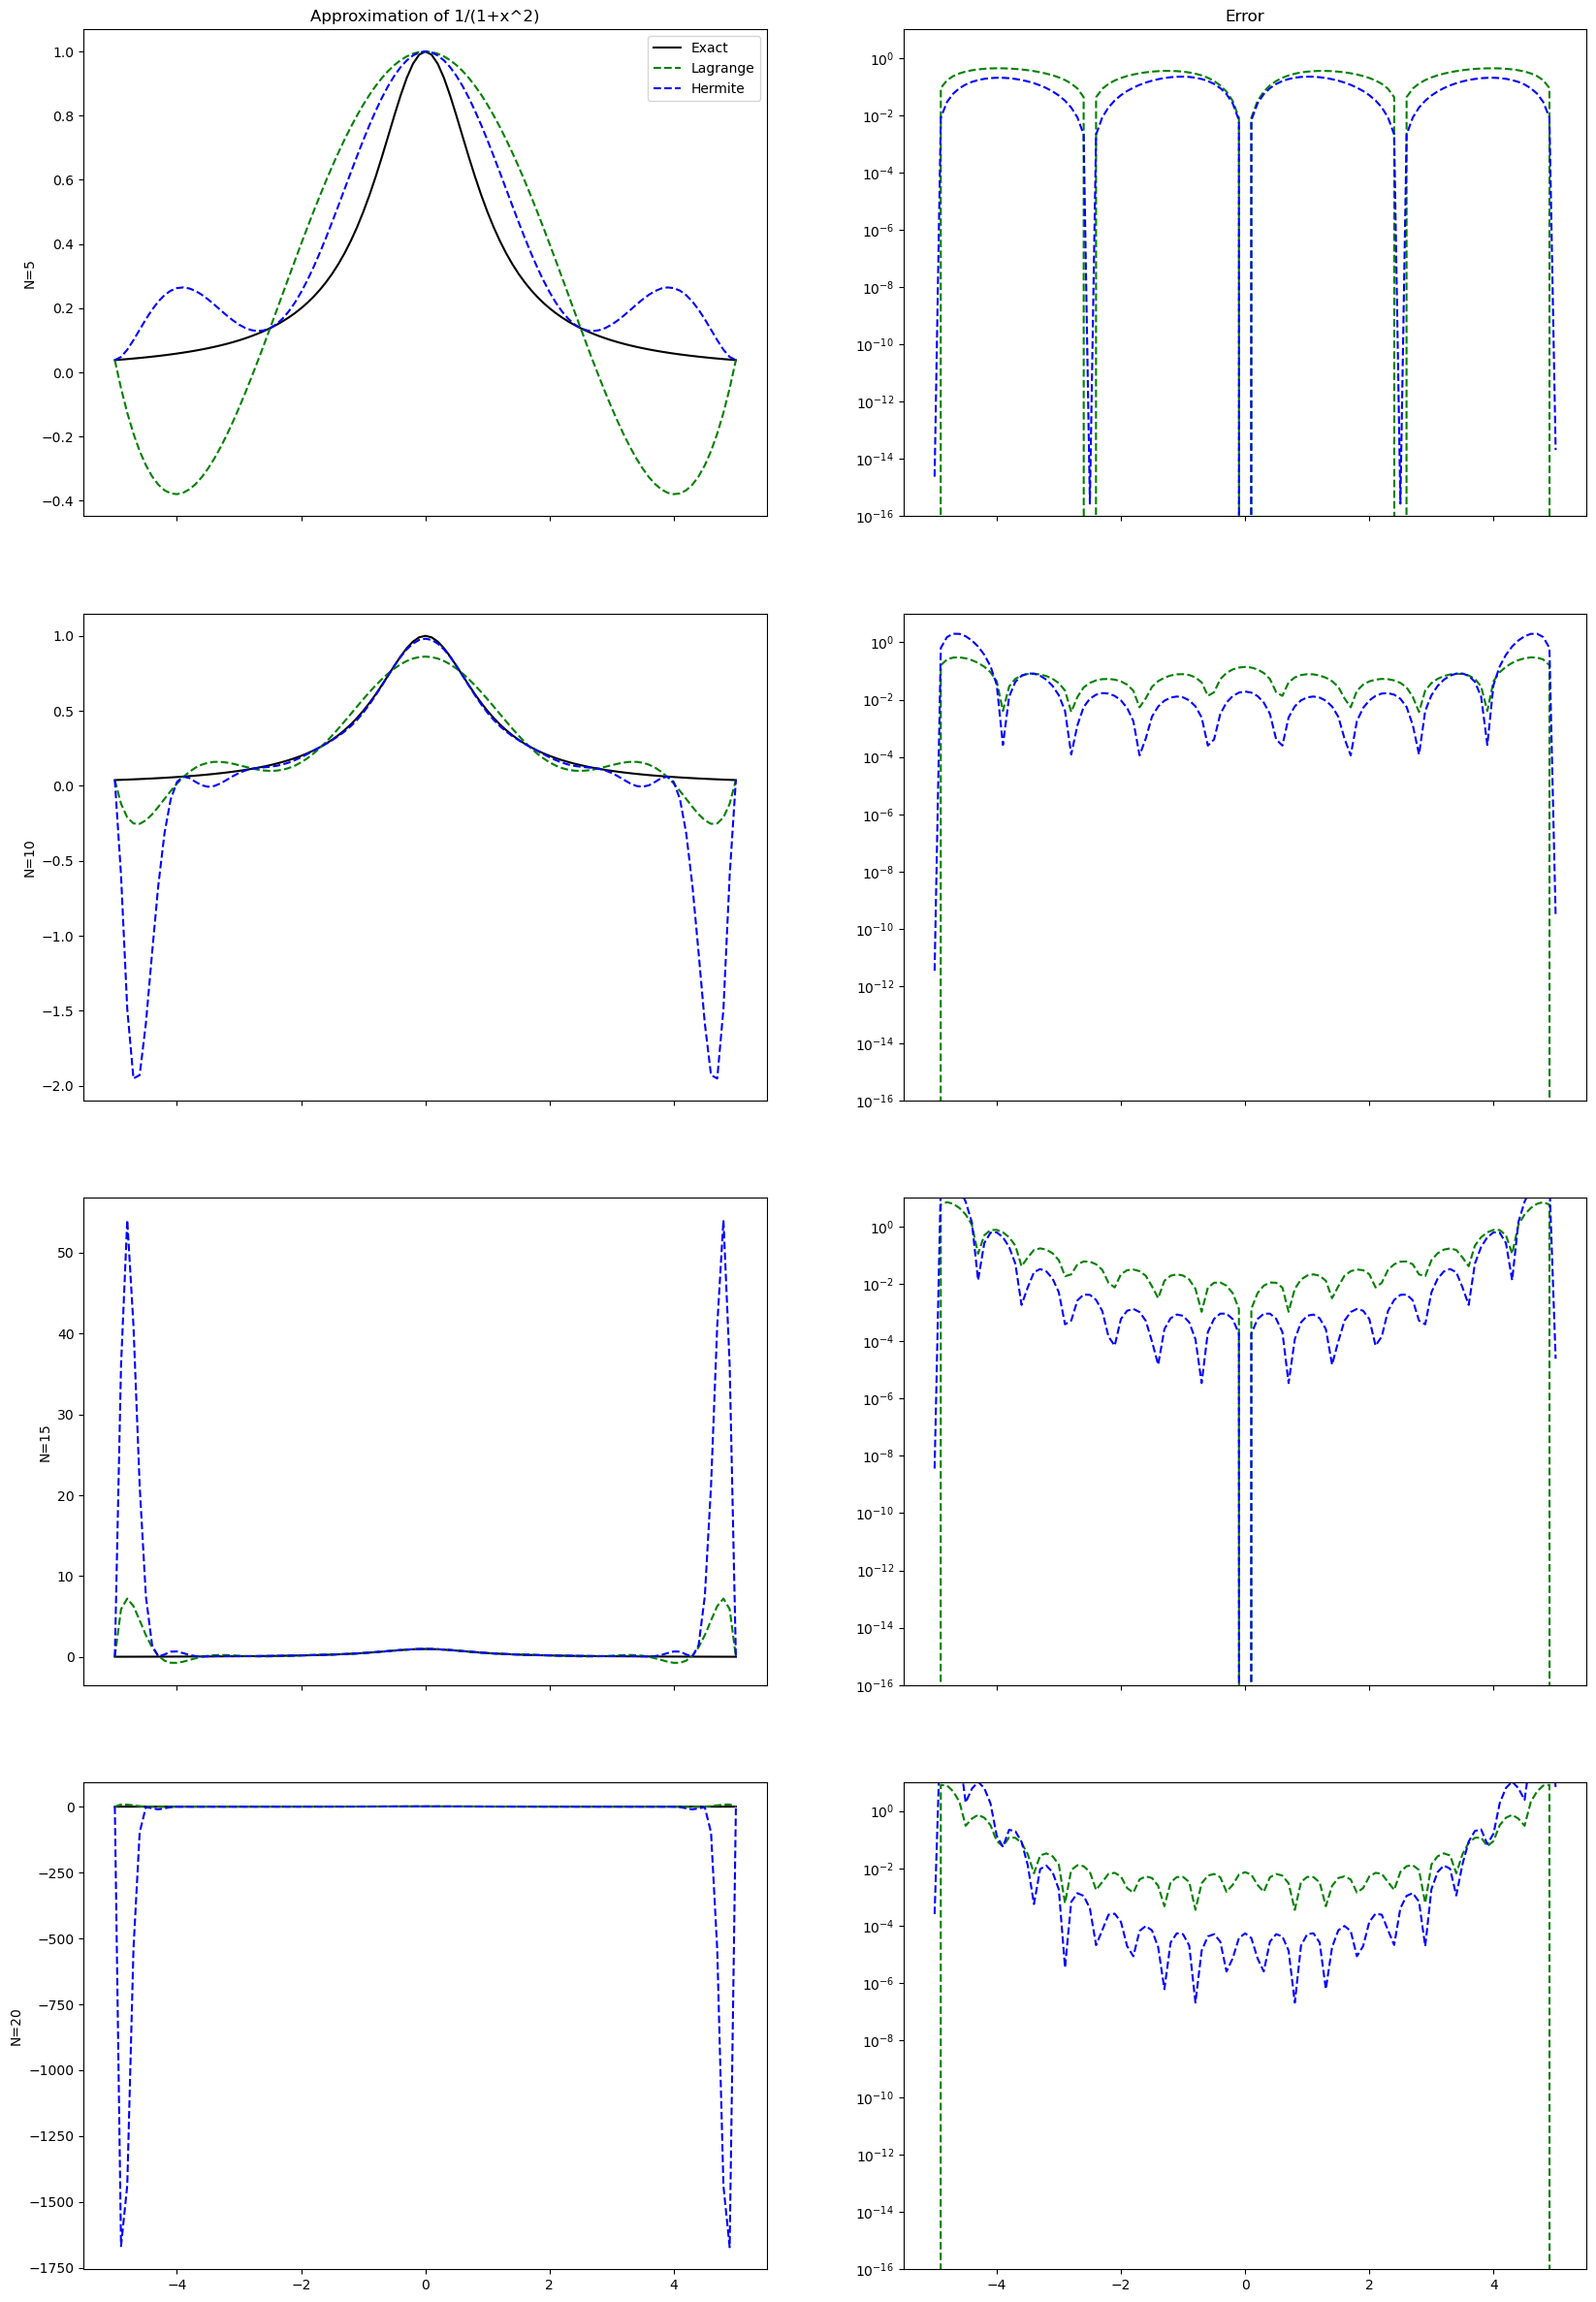

In [31]:
driver_lag_herm()